        # Twelve driver-weeks by hand, with the proxy test and the four definition lines: what does an hour count?

        **Week 4, Monday, chapter 7 of 11, the first case chapter.** It applies two of the morning's
        topics: *What to measure and why; the proxy test*, taught in
        `C2_W04_D01_01_proxy_test_STUDENT.ipynb`, and *Definitions: numerator, denominator, window,
        exclusions*, taught in `C2_W04_D01_04_numerator_denominator_window_exclusions_STUDENT.ipynb`.
        Level 1 of the case's six, which climb from a hand count (L1) to interview depth (L6): read the
        ticket, say what the number stands for, and count it by hand on twelve rows of the case's own
        data.

**The ticket. Uber, Hyderabad, the driver app's peak-hour earnings guarantee.**

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.*

On Monday 31 August 2026 the Hyderabad city team launched a peak-hour earnings guarantee for
enrolled drivers: a driver who stays online through a whole peak window (two windows a day, each
three hours long, set by the city team) is guaranteed a floor of Rs 300 per peak online hour, and
Uber pays the gap between the driver's trip earnings in the window and the floor as a top-up. The
goal written in the launch note was "more drivers on the road at peak, so riders are picked up
faster". The terms are synthetic.

Six weeks after the launch (the weeks beginning 31 August to 5 October 2026, so 31 August to 11
October) against the six weeks before (the weeks beginning 20 July to 24 August, so 20 July to 30
August):

| Measure | Before | After | Change |
|---|---|---|---|
| Peak online hours, all enrolled drivers | 118,000 | 146,300 | up 24 percent |
| Completed peak trips | 224,200 | 230,900 | up 3 percent |
| Trips per peak online hour | 1.90 | 1.58 | 1.9 to 1.6 |
| Offers accepted over offers shown, at peak | 0.86 | 0.73 | down 13 points |
| Accepted trips the driver then cancelled, share | 0.04 | 0.09 | up 5 points |
| Peak online hours with no completed trip, share | 0.22 | 0.38 | up 16 points |
| Median rider wait at peak, minutes | 4.8 | 4.6 | down 0.2 minutes |
| Rider requests at peak that went unfulfilled, share | 0.11 | 0.10 | down 1 point |
| Top-up paid | Rs 0 | Rs 1.9 crore | |

A point is one hundredth of a share, so 0.86 to 0.73 is 13 points down.

**Data the analyst has.**

| Table | Columns | Rows |
|---|---|---|
| `drivers` | `driver_id`, `home_zone`, `joined_month`, `enrolled` | 1,200 drivers, 140 of them joined after the launch |
| `driver_weeks` | `driver_id`, `week_start`, `zone_mode` (the zone where most online time was), `peak_online_hours`, `peak_offers`, `peak_accepted`, `peak_driver_cancels`, `peak_trips`, `peak_hours_no_trip`, `peak_bookings_rs`, `topup_rs`, `offpeak_trips` | one row for every driver on the app that week, twelve weeks |
| `zone_weeks` | `zone`, `week_start`, `peak_requests`, `peak_fulfilled`, `median_wait_min` | 12 zones by twelve weeks |

A rider's request that one driver declines is offered to the next driver, so `driver_weeks` counts
offers (every time a driver was shown a request) and `zone_weeks` counts rider requests.

**The ask, due Friday, to the city head.** Is the scheme working? Which metric should it pay for? Is
anyone gaming it, and how would we know?

**Known caveats.** The monsoon ended inside the after window. 140 drivers joined after the launch.
The app logs a driver as online whenever the driver app is open and the driver is marked available,
wherever the phone is. The three outer zones (Shamshabad, Rajendranagar, Patancheru) get few
requests at any hour. Drivers can be online on more than one platform at once, and Uber cannot see
the other platforms. A driver's trip earnings (the driver's share of the fares) and the window-by-window
record are not in the tables, so a week's top-up cannot be rebuilt from its bookings.

        **Who needs the answer.** The Hyderabad city head decides on Friday whether the scheme is
        working and whether to extend it. If "hours up 24 percent" is read as "more riders served"
        and it is not, the same top-up goes to two more cities.

        **The questions on the way.**

        1. What does chapter 1's proxy test ask of peak online hours?
        2. What did six drivers' hours and trips do between one week before and one week after?
        3. What is trips per peak online hour on those twelve rows, before and after?
        4. Which drivers moved it, and why do the six fall further than the city?
        5. How many of the offers shown did each driver accept?

## What does chapter 1's proxy test ask of peak online hours?

Chapter 1's canteen (invented) paid its servers per token and watched tokens double while plates
stayed at 200: the paid number drifted from the thing it stood for. The proxy test asks whether
a team could hit a number while the thing it stands for got worse or stayed the same. The
ticket's "peak online hours" counts an hour whenever the driver app is open and the driver is
marked available, wherever the phone is, so a driver can raise it with no rider served.

## What did six drivers' hours and trips do between one week before and one week after?

The twelve rows are six drivers, A to F, each in two weeks: the week beginning 10 August 2026
(before the launch) and the week beginning 21 September 2026 (after). This cell sets up the
notebook and picks those twelve driver-weeks out of `driver_weeks`. New in it: `.isin(...)`
keeps the rows whose value is in a list, `.map(...)` swaps each value for the one a dictionary
gives it, and `sort_values` puts the rows in order.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

dw = pd.read_csv("../data/C2_W04_D01_driver_weeks_STUDENT.csv")
names = {"d_0001": "A", "d_0002": "B", "d_0003": "C", "d_0004": "D", "d_0881": "E", "d_0882": "F"}
twelve = dw[dw["driver_id"].isin(names) & dw["week_start"].isin(["2026-08-10", "2026-09-21"])].copy()
twelve["driver"] = twelve["driver_id"].map(names)
twelve["week"] = twelve["week_start"].map({"2026-08-10": "before", "2026-09-21": "after"})
twelve = twelve.sort_values(["driver", "week"], ascending=[True, False])
twelve[["driver", "week", "zone_mode", "peak_online_hours", "peak_offers", "peak_accepted", "peak_trips"]]

,driver,week,zone_mode,peak_online_hours,peak_offers,peak_accepted,peak_trips
3180,A,before,Jubilee Hills,10,24,21,21
9588,A,after,Jubilee Hills,11,25,22,22
3181,B,before,Banjara Hills,9,20,17,17
9589,B,after,Banjara Hills,10,21,18,18
3182,C,before,Gachibowli,11,25,22,22
9590,C,after,Gachibowli,12,26,23,23
3183,D,before,Madhapur,10,22,19,19
9591,D,after,Madhapur,11,23,20,20
4060,E,before,Shamshabad,10,21,18,18
10468,E,after,Shamshabad,16,14,4,3


**The rate's four lines, as chapter 4 writes them.** Numerator: completed peak trips. Denominator:
peak online hours. Window: the week before the launch against the week after. Exclusions: none
on these twelve rows.

**Predict before you run.** On these six drivers, what happens to trips per peak online hour
between the two weeks? a) holds near 1.9; b) falls to about 1.6, as the city's did; c) falls
to about 1.2; d) rises above 2.0.

This cell adds up the hours and the trips in each week, then divides the two sums.

In [2]:
totals = twelve.groupby("week")[["peak_online_hours", "peak_trips"]].sum().loc[["before", "after"]]
totals["trips_per_hour"] = (totals["peak_trips"] / totals["peak_online_hours"]).round(2)
totals

,peak_online_hours,peak_trips,trips_per_hour
week,,,
before,60,114,1.90
after,74,88,1.19


**What happened.** The answer is c. The six drivers logged 60 hours and 114 trips before,
74 hours and 88 trips after: hours up 23 percent, trips down 23 percent, and trips per peak
online hour from 1.90 to 1.19. The city fell to 1.58, and the six fall further because they
were chosen to show the mechanism: two of them, E and F, logged hours with almost no trips,
a third of this sample. How common such drivers are in the city is chapter 8's question.
E and F also keep shorter weeks than most drivers who idle like them, which chapter 8's
full data shows.

## Which drivers moved the ratio, and in which direction?

This cell takes each driver's own trips per hour in both weeks and draws one line per driver.
New in it: `.pivot` turns the two weeks into two columns with one row per driver, and
`.iterrows()` walks those rows one at a time to draw each line.

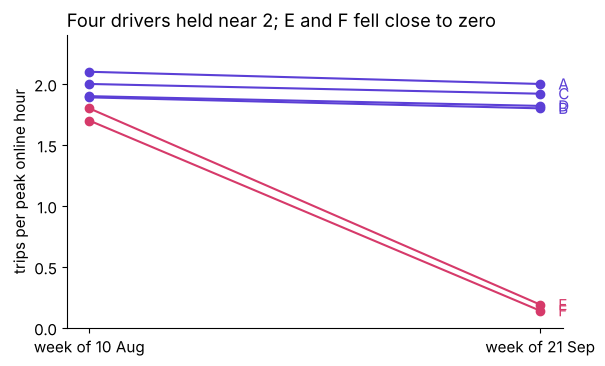

week,before,after
driver,,
A,2.10,2.00
B,1.89,1.80
C,2.00,1.92
D,1.90,1.82
E,1.80,0.19
F,1.70,0.14


In [3]:
wide = twelve.pivot(index="driver", columns="week", values=["peak_online_hours", "peak_trips"])
rate = (wide["peak_trips"] / wide["peak_online_hours"]).round(2)[["before", "after"]]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for driver, row in rate.iterrows():
    colour = ROSE if driver in "EF" else VIOLET
    ax.plot([0, 1], [row["before"], row["after"]], marker="o", color=colour)
    ax.text(1.04, row["after"], driver, color=colour, va="center")
ax.set_xticks([0, 1], ["week of 10 Aug", "week of 21 Sep"])
ax.set_ylim(0, 2.4)
ax.set_ylabel("trips per peak online hour")
ax.set_title("Four drivers held near 2; E and F fell close to zero", loc="left")
plt.show()
rate

**What happened.** A to D held between 1.80 and 2.10 trips an hour. E went from 10 hours and
18 trips to 16 hours and 3 trips; F went from 10 hours and 17 trips to 14 hours and 2 trips.
Both sit in outer zones (Shamshabad and Rajendranagar), where riders ask for few trips at any
hour. Their hours went up and their trips nearly vanished: the proxy rose while the thing it
stands for fell.

This cell draws the six drivers' hours and trips as two pairs of bars, the picture the
hand count makes.

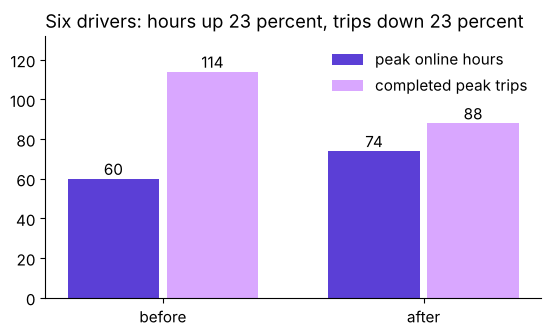

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar([0, 1], totals["peak_online_hours"], width=0.35, color=VIOLET, label="peak online hours")
ax.bar([0.38, 1.38], totals["peak_trips"], width=0.35, color=LAV, label="completed peak trips")
for x, v in zip([0, 1, 0.38, 1.38], list(totals["peak_online_hours"]) + list(totals["peak_trips"])):
    ax.text(x, v + 2, str(v), ha="center")
ax.set_xticks([0.19, 1.19], ["before", "after"])
ax.set_ylim(0, 132)
ax.set_title("Six drivers: hours up 23 percent, trips down 23 percent", loc="left")
ax.legend(frameon=False, loc="upper right")
plt.show()

## How many of the offers shown did each driver accept?

A driver who stays online without driving shows first in what that driver does with the offers
the app shows. This cell draws each driver's offers shown and offers accepted in the week after
the launch.

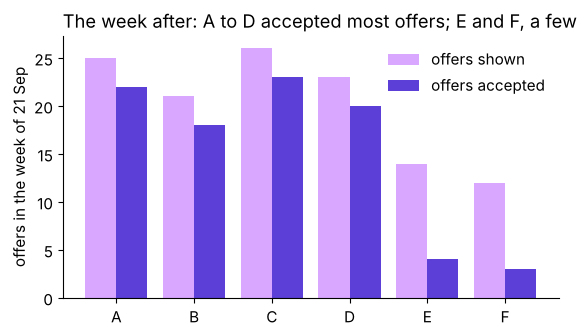

,peak_offers,peak_accepted
driver,,
A,25,22
B,21,18
C,26,23
D,23,20
E,14,4
F,12,3


In [5]:
after_rows = twelve[twelve["week"] == "after"].set_index("driver")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar([i - 0.2 for i in range(6)], after_rows["peak_offers"], width=0.4, color=LAV, label="offers shown")
ax.bar([i + 0.2 for i in range(6)], after_rows["peak_accepted"], width=0.4, color=VIOLET, label="offers accepted")
ax.set_xticks(range(6), after_rows.index)
ax.set_ylabel("offers in the week of 21 Sep")
ax.set_title("The week after: A to D accepted most offers; E and F, a few", loc="left")
ax.legend(frameon=False, loc="upper right")
plt.show()
after_rows[["peak_offers", "peak_accepted"]]

**What happened.** A to D accepted most of what they were shown. E accepted 4 of the 14 offers
it was shown and F 3 of 12: both stayed online and declined.

This cell checks the claims the chapter makes about its own numbers.

In [6]:
check("the twelve rows are six drivers in two weeks", len(twelve) == 12 and twelve["driver"].nunique() == 6)
check("hours 60 before and 74 after", list(totals["peak_online_hours"]) == [60, 74])
check("trips 114 before and 88 after", list(totals["peak_trips"]) == [114, 88])
check("trips per peak online hour 1.90 before and 1.19 after", list(totals["trips_per_hour"]) == [1.90, 1.19])
check("E and F fell below 0.25 trips an hour after the launch", (rate.loc[["E", "F"], "after"] < 0.25).all())
check("E accepted 4 of 14 offers and F 3 of 12 after the launch",
      after_rows.loc[["E", "F"], ["peak_accepted", "peak_offers"]].values.tolist() == [[4, 14], [3, 12]])

PASS the twelve rows are six drivers in two weeks
PASS hours 60 before and 74 after
PASS trips 114 before and 88 after
PASS trips per peak online hour 1.90 before and 1.19 after
PASS E and F fell below 0.25 trips an hour after the launch
PASS E accepted 4 of 14 offers and F 3 of 12 after the launch


## What does chapter 7 answer?

1. Peak online hours count an hour whenever the driver app is open, so they fail chapter 1's
   proxy test: a driver can raise them with no rider served.
2. The six drivers' hours rose from 60 to 74 while their trips fell from 114 to 88.
3. Trips per peak online hour on the twelve rows, completed peak trips over peak online hours
   in the week before against the week after, fell from 1.90 to 1.19.
4. E and F moved it: their hours rose while their trips fell to 3 and 2. The six fall further
   than the city's 1.58 because they were chosen to show the mechanism.
5. E accepted 4 of 14 offers and F 3 of 12, while A to D accepted most of theirs.

**The check a senior analyst runs before trusting a rate.** Read its baseline (1.90 before),
its denominator (hours the app was open, which a driver controls) and the evidence that the
thing it stands for moved (trips rose only 3 percent across the city).

**In the interview.** [S] How would you measure the success of a new feature? ([S] marks a staple asked everywhere, [F] one frequent in GCC and product screens and [D] a differentiator: the curriculum's own calibration for early-career candidates in India.) A
hire-grade answer starts from what the feature is for and names a number that cannot rise while
that thing gets worse. Notebook 08 runs the same count on all 12,860 driver-weeks.